In [1]:
import scanpy as sc
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
INDIR = Path.home()/'project/crc-pm/result/latest.h5ad'
adata = sc.read_h5ad(INDIR)
adata_str = adata[adata.obs['Compartment'] == 'Stromal']
del adata

In [3]:
sc.pp.neighbors(
    adata_str,
    use_rep="X_scVI",
    n_neighbors=20,
    metric="cosine",
    random_state=42,
)

sc.tl.umap(
    adata_str,
    min_dist=0.25,
    random_state=2026,)

# use different res
leiden_res = [0.125, 0.25, 0.5, 1.0]
for i in leiden_res:
    sc.tl.leiden(adata_str, key_added=f"leiden_res{i}", resolution=i, flavor="igraph", n_iterations=2)


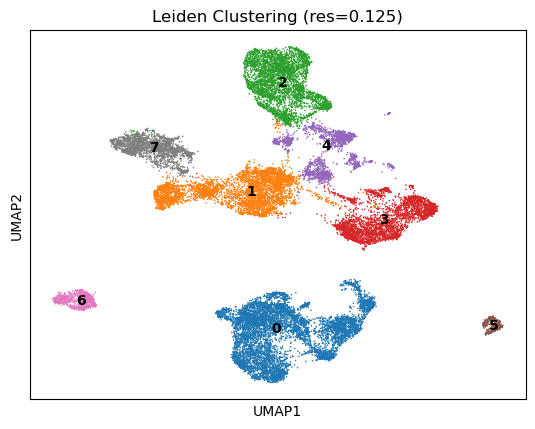

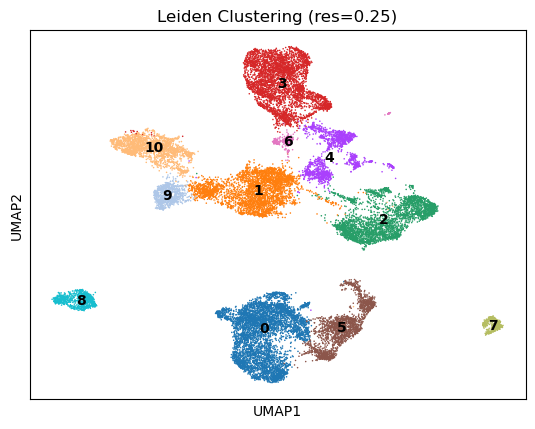

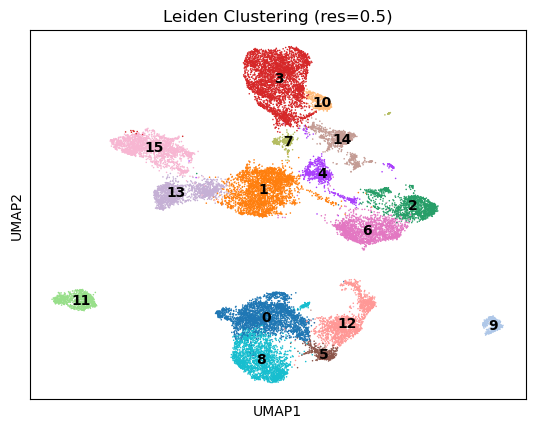

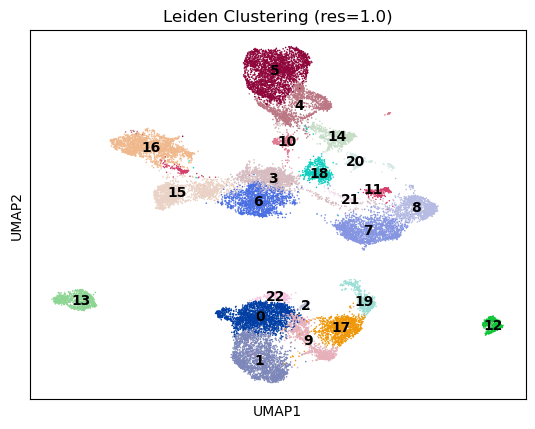

In [4]:
for i in leiden_res:
    sc.pl.umap(
        adata_str,
        color=f"leiden_res{i}",
        legend_loc="on data",
        title=f"Leiden Clustering (res={i})",
    )

/home/zhekai/miniconda3/envs/pm/lib/python3.13/site-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


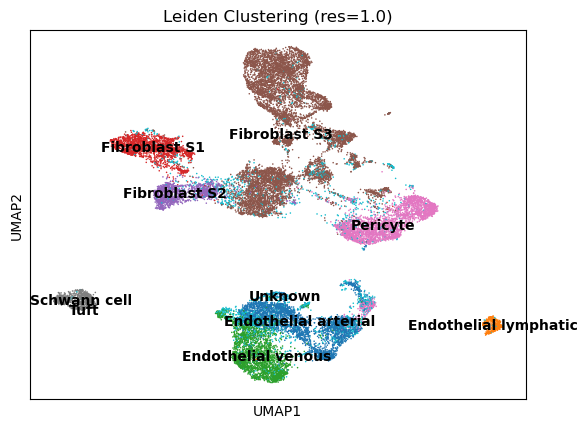

In [5]:
sc.pl.umap(
        adata_str[~adata_str.obs['scANVI_CellType'].isin(['Cancer Crypt-like','Plasma IgM','Macrophage'])],
        color='scANVI_CellType',
        legend_loc="on data",
        title=f"Leiden Clustering (res={i})",
    )

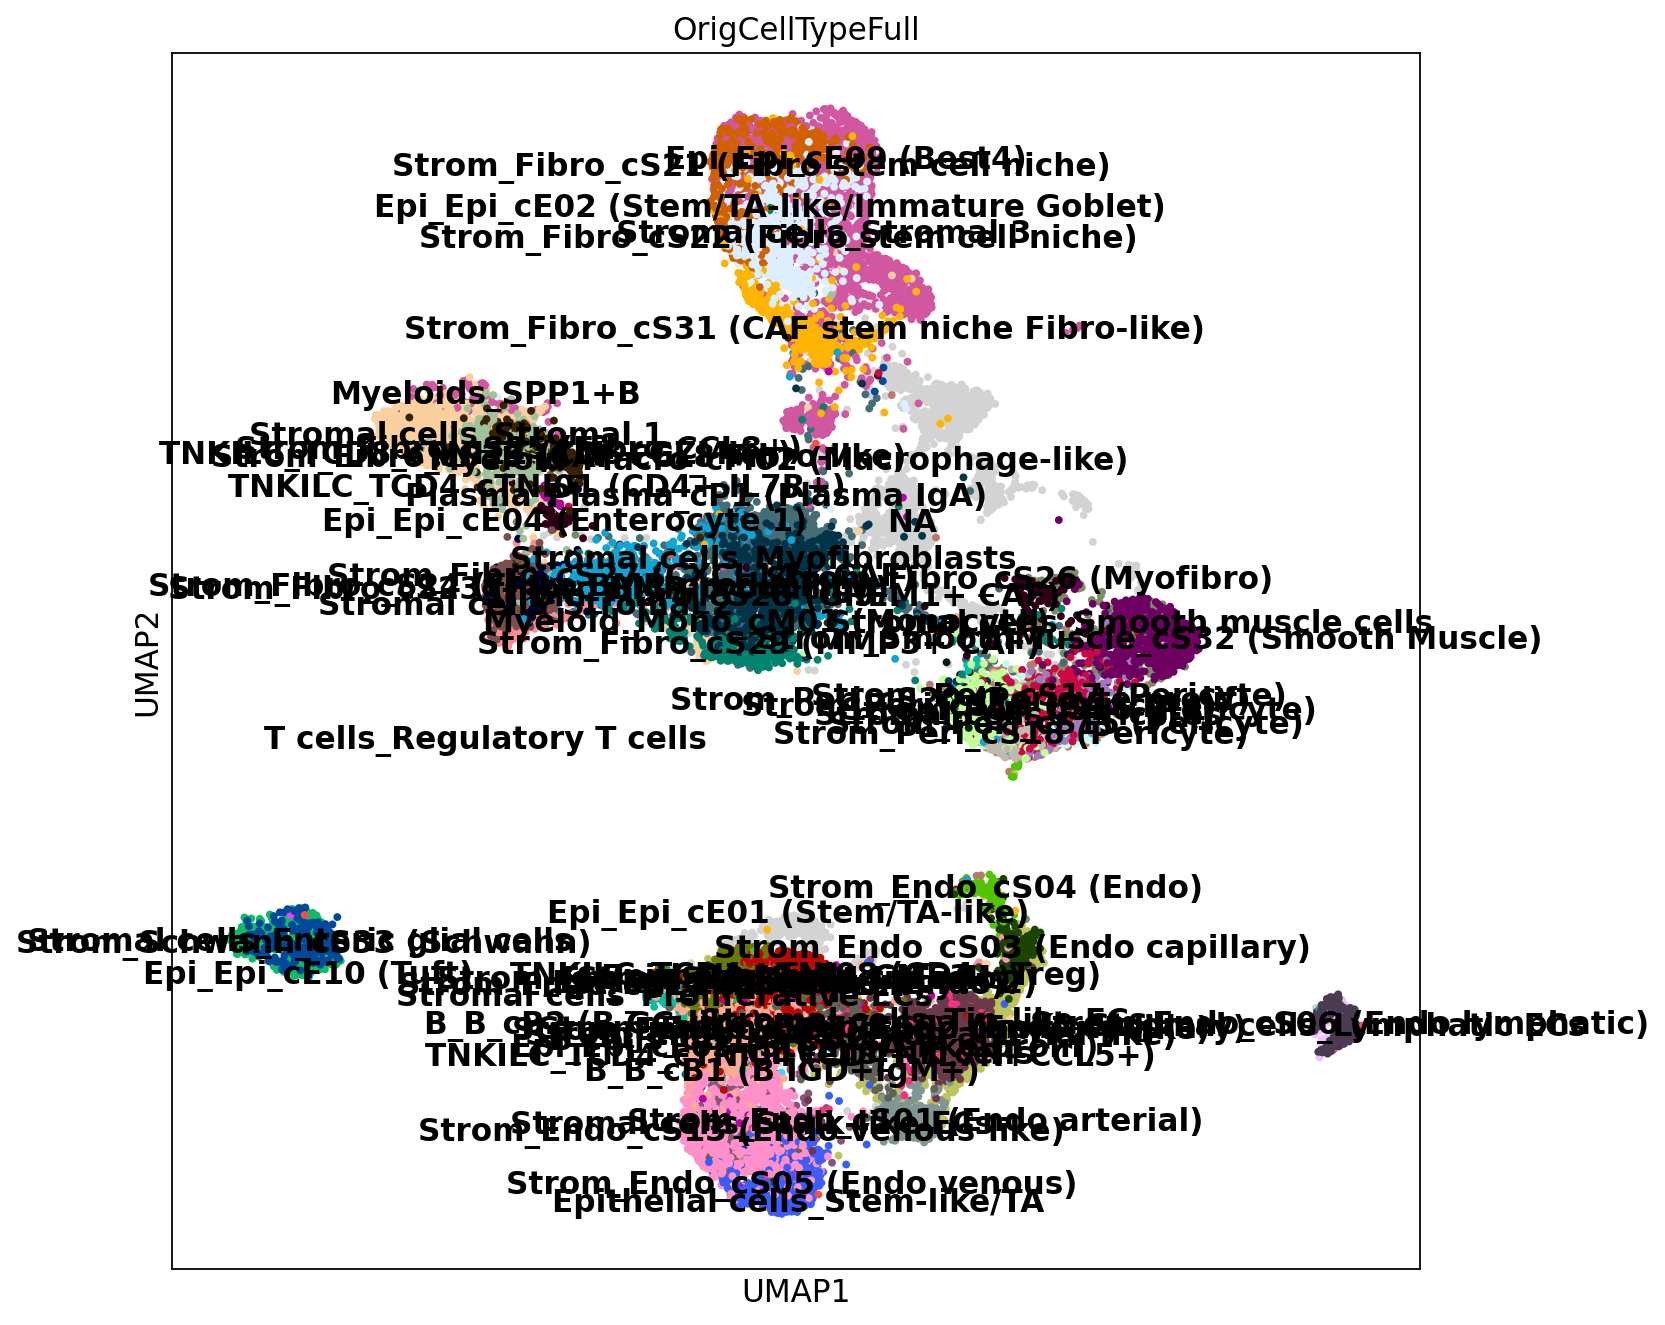

In [6]:
sc.set_figure_params(figsize=(10, 10))
sc.pl.umap(
        adata_str,
        color="OrigCellTypeFull",
        legend_loc="on data",
        s = 50,
    )

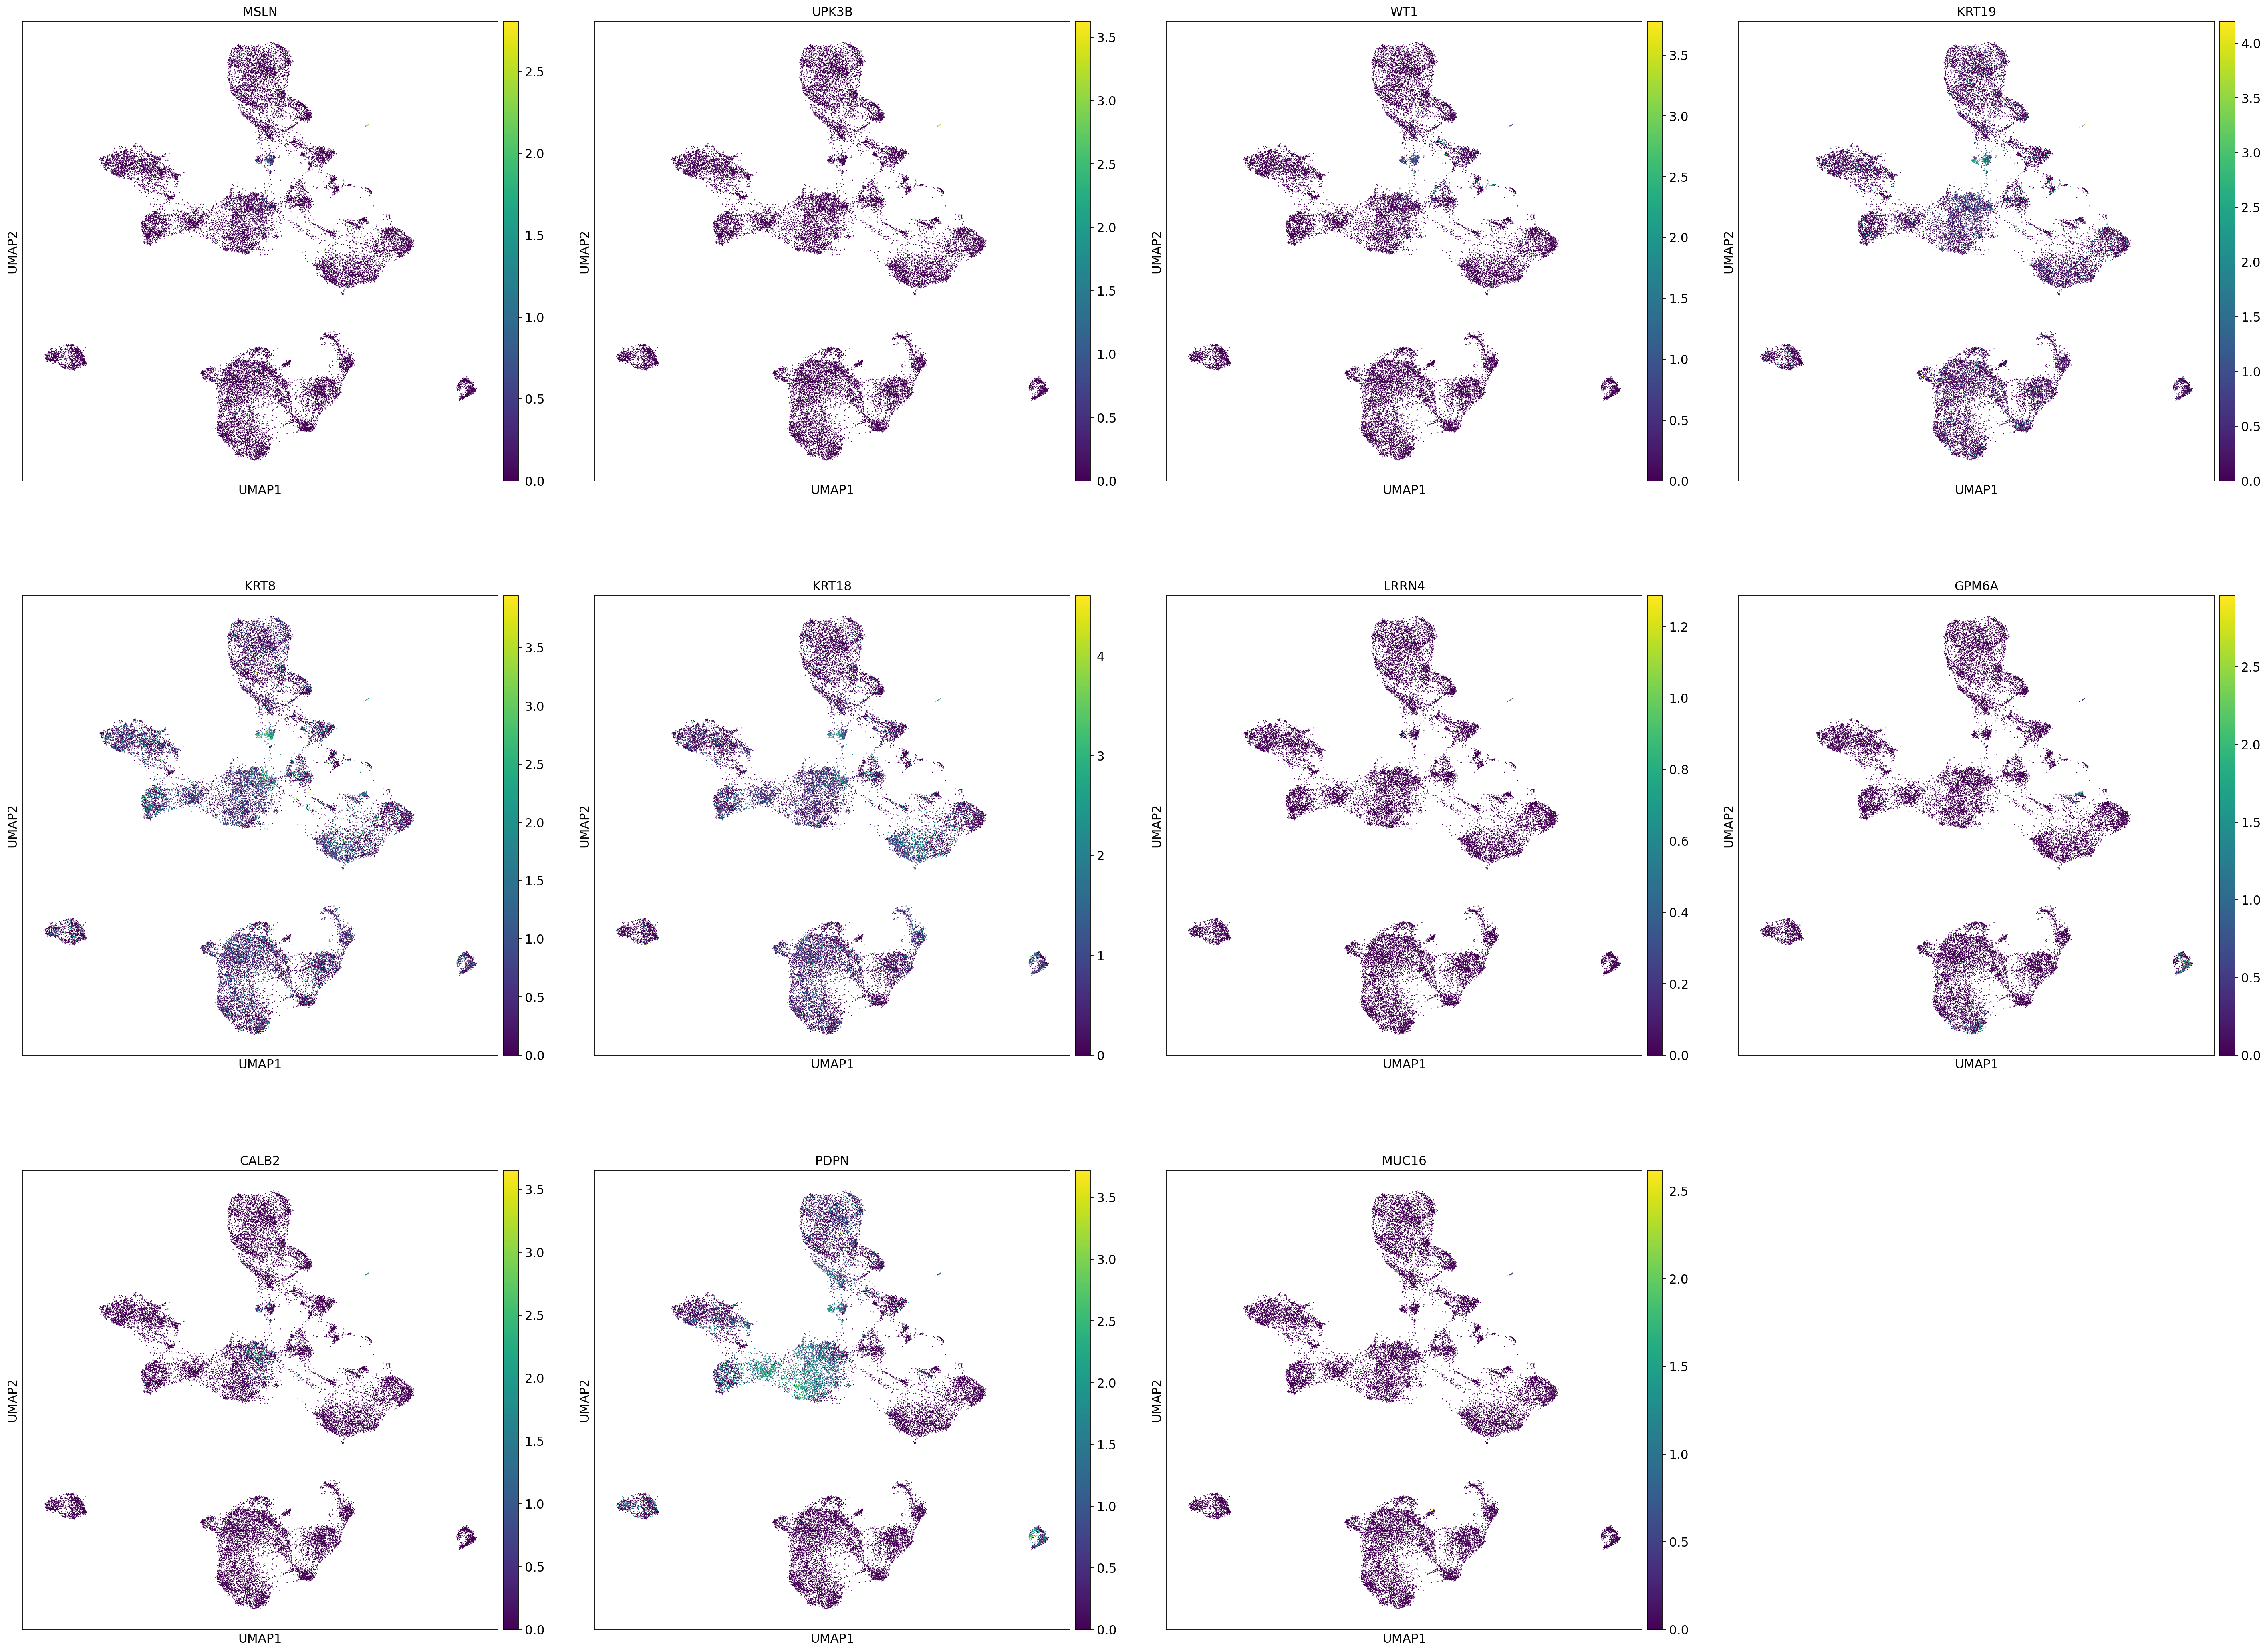

In [7]:
MESO_MARKERS = ['MSLN', 'UPK3B', 'WT1', 'KRT19', 'KRT8', 'KRT18', 'LRRN4', 'GPM6A', 'CALB2', 'PDPN', 'MUC16']
sc.pl.umap(
        adata_str[~adata_str.obs['scANVI_CellType'].isin(['Cancer Crypt-like','Plasma IgM','Macrophage'])],
        color=MESO_MARKERS,
        gene_symbols="gene_name",
        layer="log1p",
    )

In [8]:
condition = 'crc'
{
    'crc':'red',
    'pm':'orange',
    'healthy':'blue'
}[condition]

'red'

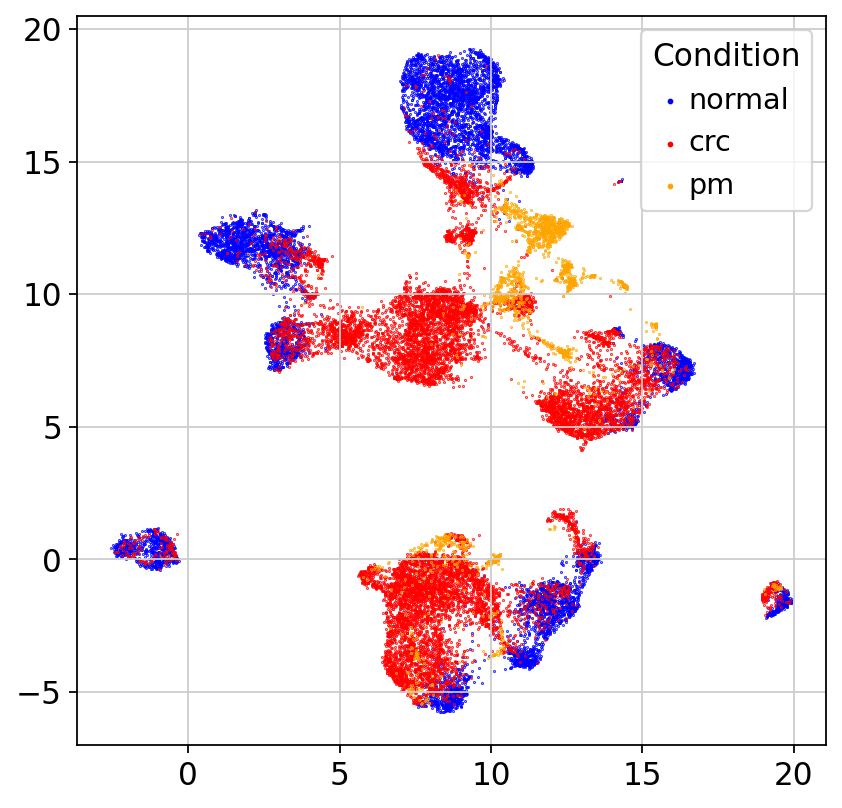

In [9]:
fig, ax = plt.subplots(figsize = (6,6))
for condition in ['normal','crc', 'pm',]:
    adata = adata_str[adata_str.obs['Tissue'] == condition ]
    ax.scatter(
        x = adata.obsm['X_umap'][:,0],
        y = adata.obsm['X_umap'][:,1],
        s = 0.1,
        c = {
                'crc':'red',
                'pm':'orange',
                'normal':'blue'
            }[condition],
        label = condition,
        
    )
ax.legend(title='Condition', markerscale=5)
plt.show()

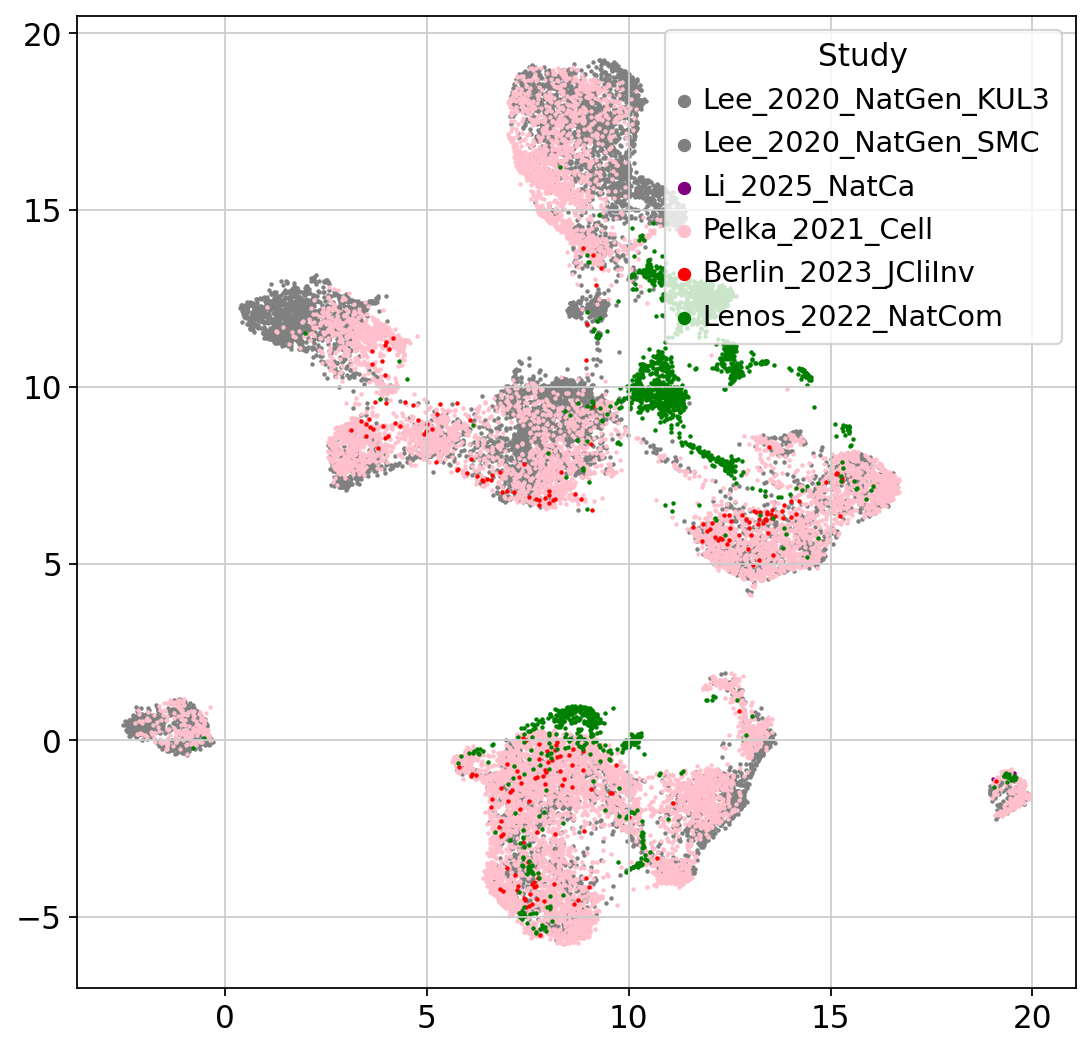

In [10]:
fig, ax = plt.subplots(figsize = (8,8))
for study in ['Lee_2020_NatGen_KUL3', 'Lee_2020_NatGen_SMC', 'Li_2025_NatCa', 'Pelka_2021_Cell','Berlin_2023_JCliInv', 'Lenos_2022_NatCom',]:
    adata = adata_str[adata_str.obs['Study'] == study ]
    ax.scatter(
        x = adata.obsm['X_umap'][:,0],
        y = adata.obsm['X_umap'][:,1],
        s = 1,
        c = {
                'Lee_2020_NatGen_KUL3':'grey',
                'Lee_2020_NatGen_SMC':'grey',
                'Berlin_2023_JCliInv':'red',
                'Li_2025_NatCa':'purple',
                'Lenos_2022_NatCom':'green',
                'Pelka_2021_Cell':'pink',
            }[study],
        label = study,
    )
ax.legend(title='Study', markerscale=5)
plt.show()


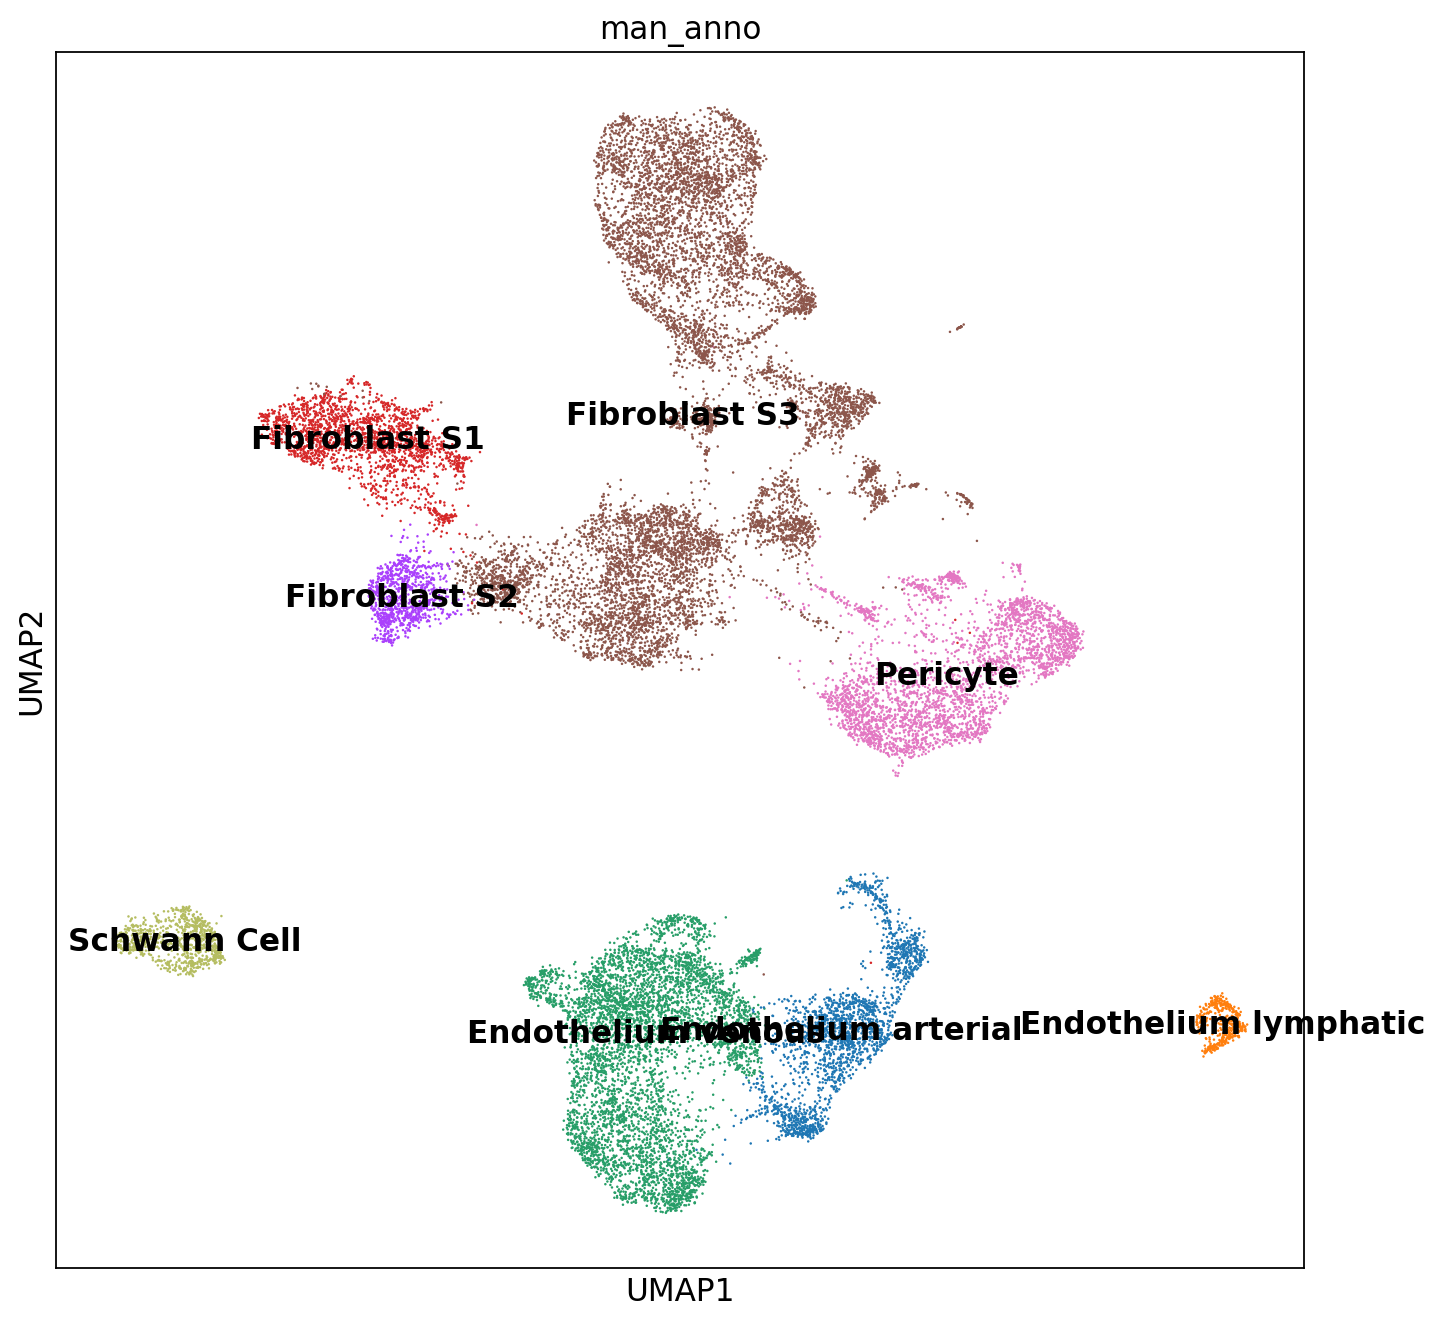

In [12]:
dict_res_025 = {
    '0': 'Endothelium venous',
    '1' : 'Fibroblast S3',
    '2' : 'Pericyte',
    '3' : 'Fibroblast S3',
    '4' : 'Fibroblast S3',
    '5' : 'Endothelium arterial',
    '6' : 'Fibroblast S3',
    '7' : 'Endothelium lymphatic',
    '8' : 'Schwann Cell',
    '9' : 'Fibroblast S2',
    '10' : 'Fibroblast S1',
}
adata_str.obs['man_anno'] = adata_str.obs['leiden_res0.25'].map(dict_res_025)
sc.pl.umap(adata_str, color = 'man_anno',legend_loc="on data", )